In [11]:
# ============================================================
# HISTORIA DE DATOS:
# "DEL ACCESO A LA CONEXIÓN"
# Acceso a Internet en las escuelas para fines pedagógicos
# ============================================================


# ============================================================
# CELDA 1 - IMPORTAR LIBRERÍAS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pycountry

from IPython.display import display, Markdown

# Configuración general de gráficos
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.titlesize"] = 15
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["xtick.labelsize"] = 10
plt.rcParams["ytick.labelsize"] = 10


# ============================================================
# CELDA 2 - CARGAR EL CSV
# ============================================================

# Cambia la ruta si tu archivo se encuentra en otra carpeta
archivo = "SE_ACS_INTNT.csv"

df = pd.read_csv(archivo)

print("Archivo cargado correctamente.")
print(f"Filas: {df.shape[0]:,}")
print(f"Columnas: {df.shape[1]}")


# ============================================================
# CELDA 3 - CONOCER NUESTROS DATOS
# ============================================================

print("Dimensiones del dataset:")
print(df.shape)

print("\nColumnas:")
print(df.columns.tolist())

print("\nPrimeras 5 filas:")
display(df.head())

Archivo cargado correctamente.
Filas: 4,412
Columnas: 22
Dimensiones del dataset:
(4412, 22)

Columnas:
['DATAFLOW', 'SERIES', 'GEOGRAPHY', 'EDUCATION_LEVEL', 'TIME_PERIOD', 'OBS_VALUE', 'RELEASE_STATUS', 'RELEASE_NAME', 'GEOGRAPHY_TYPE', 'TIME_DETAIL', 'TIME_COVERAGE', 'UNIT_MEASURE', 'UNIT_MULTIPLIER', 'BASE_PERIOD', 'VALUE_TYPE', 'UPPER_BOUND', 'LOWER_BOUND', 'NATURE', 'OBSERVATION_STATUS', 'REPORTING_LEVEL', 'SOURCE', 'FOOT_NOTE']

Primeras 5 filas:


,DATAFLOW,SERIES,GEOGRAPHY,EDUCATION_LEVEL,TIME_PERIOD,OBS_VALUE,RELEASE_STATUS,RELEASE_NAME,GEOGRAPHY_TYPE,TIME_DETAIL,...,UNIT_MULTIPLIER,BASE_PERIOD,VALUE_TYPE,UPPER_BOUND,LOWER_BOUND,NATURE,OBSERVATION_STATUS,REPORTING_LEVEL,SOURCE,FOOT_NOTE
0,UNDATA:SE_ACS_INTNT(1.0),SE_ACS_INTNT,G00000050,AGG_2T3,2012,76.80372,Published,2025.Q1.G.02,G,2012,...,0,NaN,Float,NaN,NaN,C,_T,G,UIS based on PISA 2012 Data extracted on 25 Fe...,NaN
1,UNDATA:SE_ACS_INTNT(1.0),SE_ACS_INTNT,G00000050,AGG_2T3,2018,74.40217,Published,2025.Q1.G.02,G,2018,...,0,NaN,Float,NaN,NaN,C,_T,G,NA Data extracted on 25 February 2025.,NaN
2,UNDATA:SE_ACS_INTNT(1.0),SE_ACS_INTNT,G00000050,AGG_2T3,2019,85.90034,Published,2025.Q1.G.02,G,2019,...,0,NaN,Float,NaN,NaN,C,_T,G,NA Data extracted on 25 February 2025.,NaN
3,UNDATA:SE_ACS_INTNT(1.0),SE_ACS_INTNT,G00000050,AGG_2T3,2020,100.00000,Published,2025.Q1.G.02,G,2020,...,0,NaN,Float,NaN,NaN,C,_T,G,NA Data extracted on 25 February 2025.,NaN
4,UNDATA:SE_ACS_INTNT(1.0),SE_ACS_INTNT,G00000050,AGG_2T3,2021,70.77844,Published,2025.Q1.G.02,G,2021,...,0,NaN,Float,NaN,NaN,C,_T,G,NA Data extracted on 25 February 2025.,NaN


In [13]:

# ============================================================
# CELDA 4 - LIMPIEZA Y PREPARACIÓN
# ============================================================

# Copia para conservar intacto el archivo original
datos = df.copy()

# Convertimos las variables importantes a formato numérico
datos["TIME_PERIOD"] = pd.to_numeric(
    datos["TIME_PERIOD"], errors="coerce"
)

datos["OBS_VALUE"] = pd.to_numeric(
    datos["OBS_VALUE"], errors="coerce"
)

# Eliminamos registros que no tengan año o valor
datos = datos.dropna(
    subset=["TIME_PERIOD", "OBS_VALUE"]
)

# Creamos una variable de año
datos["AÑO"] = datos["TIME_PERIOD"].astype(int)

print(f"Registros después de la limpieza: {len(datos):,}")


# ============================================================
# CELDA 5 - IDENTIFICAR EL SIGNIFICADO DEL INDICADOR
# ============================================================

print("""
INDICADOR:

SE_ACS_INTNT

Proporción de escuelas con acceso a Internet
para fines pedagógicos, expresada en porcentaje.

La variable OBS_VALUE representa el porcentaje.
Por lo tanto:

0   = 0% de escuelas
50  = 50% de escuelas
100 = 100% de escuelas
""")

print("Unidad de medida encontrada:")
print(datos["UNIT_MEASURE"].unique())


Registros después de la limpieza: 4,412

INDICADOR:

SE_ACS_INTNT

Proporción de escuelas con acceso a Internet
para fines pedagógicos, expresada en porcentaje.

La variable OBS_VALUE representa el porcentaje.
Por lo tanto:

0   = 0% de escuelas
50  = 50% de escuelas
100 = 100% de escuelas

Unidad de medida encontrada:
['PT']


In [15]:
# ============================================================
# CELDA 6 - REVISIÓN DE LOS NIVELES EDUCATIVOS
# ============================================================

print("Niveles educativos encontrados:")

display(
    datos["EDUCATION_LEVEL"]
    .value_counts()
    .rename_axis("Nivel educativo")
    .reset_index(name="Cantidad")
)


# Diccionario para que los gráficos sean más fáciles de entender
nombres_nivel = {
    "ISCED11_1": "Primaria",
    "ISCED11_2": "Secundaria baja",
    "ISCED11_3": "Secundaria alta",
    "AGG_2T3": "Secundaria (2+3)"
}

datos["NIVEL"] = datos["EDUCATION_LEVEL"].map(
    nombres_nivel
).fillna(datos["EDUCATION_LEVEL"])



# ============================================================
# CELDA 7 - IDENTIFICAR LOS PAÍSES / GEOGRAFÍAS
# ============================================================

# Los códigos GEOGRAPHY utilizan códigos numéricos M49
# incorporados dentro del código de Naciones Unidas.

def obtener_pais(codigo):
    
    # Tomamos los últimos tres caracteres
    codigo_m49 = str(codigo)[-3:]
    
    try:
        numero = int(codigo_m49)
        
        pais = pycountry.countries.get(
            numeric=f"{numero:03d}"
        )
        
        if pais:
            return pais.name
        
        return f"Geografía {codigo}"
    
    except:
        return f"Geografía {codigo}"


datos["PAIS"] = datos["GEOGRAPHY"].apply(obtener_pais)

print("Ejemplo de las geografías identificadas:")
display(
    datos[["GEOGRAPHY", "PAIS"]]
    .drop_duplicates()
    .head(20)
)

Niveles educativos encontrados:


,Nivel educativo,Cantidad
0,ISCED11_1,1138
1,ISCED11_3,1118
2,ISCED11_2,1102
3,AGG_2T3,1054


Ejemplo de las geografías identificadas:


,GEOGRAPHY,PAIS
0,G00000050,Bangladesh
19,G00000060,Bermuda
31,G00000080,Geografía G00000080
63,G00000090,Solomon Islands
67,G00000100,Bulgaria
79,G00000120,Cameroon
86,G00000130,Geografía G00000130
124,G00000140,Central African Republic
148,G00000170,Colombia
237,G00000180,"Congo, The Democratic Republic of the"


In [17]:

# ============================================================
# CELDA 8 - PRIMERA PREGUNTA DE LA HISTORIA
# ¿CUÁNTO HA CAMBIADO LA INFORMACIÓN A TRAVÉS DEL TIEMPO?
# ============================================================

resumen_anual = (
    datos
    .groupby("AÑO")
    .agg(
        promedio=("OBS_VALUE", "mean"),
        mediana=("OBS_VALUE", "median"),
        observaciones=("OBS_VALUE", "count")
    )
    .reset_index()
)

display(resumen_anual.round(2))


,AÑO,promedio,mediana,observaciones
0,2000,97.87,100.00,42
1,2001,98.31,100.00,41
2,2002,96.63,100.00,45
3,2003,97.04,100.00,46
4,2004,97.48,100.00,49
5,2005,97.91,100.00,53
6,2006,98.17,100.00,49
7,2007,95.74,100.00,52
8,2008,98.51,100.00,52
9,2009,88.75,100.00,67


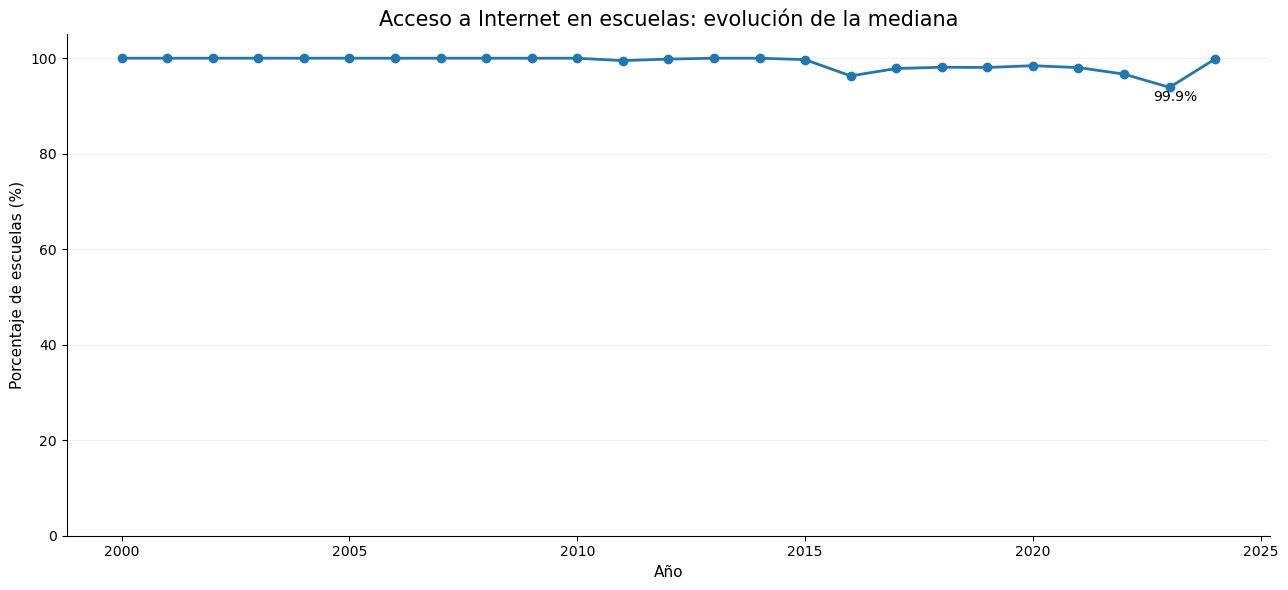


LECTURA DEL GRÁFICO

La mediana permite observar el comportamiento central de los
registros sin que unos pocos valores extremadamente bajos o altos
dominen completamente la lectura.

El gráfico muestra que una gran parte de los registros se encuentra
cerca de niveles altos de acceso.

Sin embargo, NO debemos interpretar esta línea como una medición
perfectamente comparable del promedio mundial, porque la cantidad
de observaciones disponibles cambia considerablemente de un año
a otro.



In [19]:
# ============================================================
# CELDA 9 - GRÁFICO 1
# EVOLUCIÓN DEL ACCESO A INTERNET
# ============================================================

fig, ax1 = plt.subplots(figsize=(13, 6))

ax1.plot(
    resumen_anual["AÑO"],
    resumen_anual["mediana"],
    marker="o",
    linewidth=2,
    label="Mediana"
)

ax1.set_title(
    "Acceso a Internet en escuelas: evolución de la mediana"
)

ax1.set_xlabel("Año")
ax1.set_ylabel("Porcentaje de escuelas (%)")

ax1.set_ylim(0, 105)

# Eliminamos elementos innecesarios
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)

ax1.grid(
    axis="y",
    alpha=0.2
)

# Anotación del último dato
ultimo = resumen_anual.iloc[-1]

ax1.annotate(
    f"{ultimo['mediana']:.1f}%",
    xy=(ultimo["AÑO"], ultimo["mediana"]),
    xytext=(-45, -30),
    textcoords="offset points",
    fontsize=10
)

plt.tight_layout()
plt.show()


# ============================================================
# CELDA 10 - ANOTACIÓN INTERPRETATIVA
# ============================================================

print("""
LECTURA DEL GRÁFICO

La mediana permite observar el comportamiento central de los
registros sin que unos pocos valores extremadamente bajos o altos
dominen completamente la lectura.

El gráfico muestra que una gran parte de los registros se encuentra
cerca de niveles altos de acceso.

Sin embargo, NO debemos interpretar esta línea como una medición
perfectamente comparable del promedio mundial, porque la cantidad
de observaciones disponibles cambia considerablemente de un año
a otro.
""")

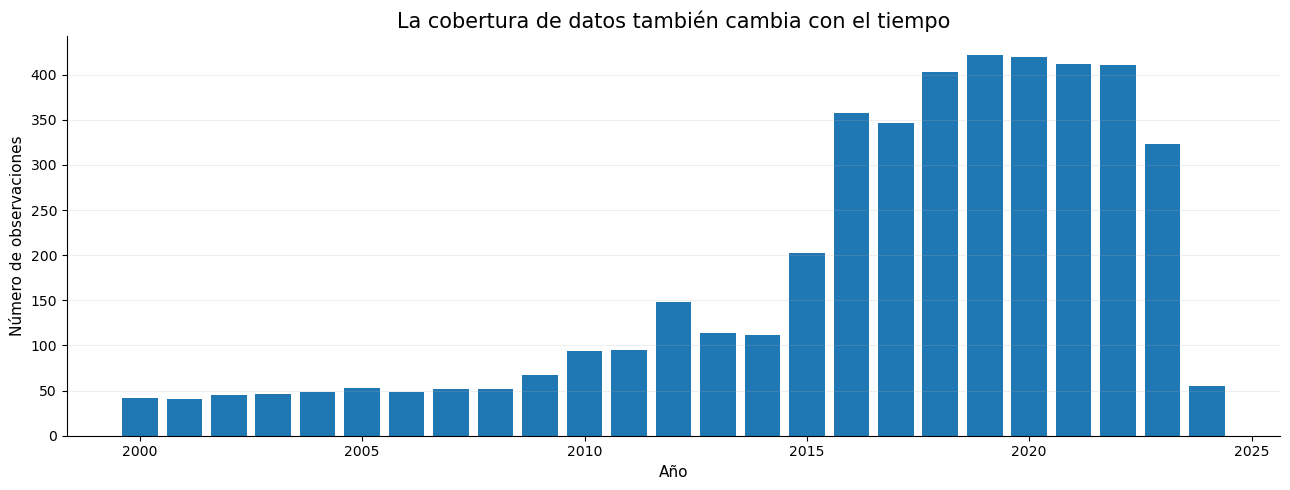


ALERTA DE INTERPRETACIÓN

Este gráfico es importante porque nos recuerda que una tendencia
estadística también depende de cuántos datos tenemos disponibles.

Por ejemplo, algunos años tienen cientos de observaciones mientras
que otros tienen muchas menos.

Por eso, en lugar de decir:

"El mundo aumentó o disminuyó exactamente X puntos porcentuales",

es más correcto decir:

"Entre los registros disponibles se observa este comportamiento".

Esto evita una conclusión exagerada.



In [21]:
# ============================================================
# CELDA 11 - ¿CUÁNTAS OBSERVACIONES TENEMOS POR AÑO?
# ============================================================

fig, ax = plt.subplots(figsize=(13, 5))

ax.bar(
    resumen_anual["AÑO"],
    resumen_anual["observaciones"]
)

ax.set_title(
    "La cobertura de datos también cambia con el tiempo"
)

ax.set_xlabel("Año")
ax.set_ylabel("Número de observaciones")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(
    axis="y",
    alpha=0.2
)

plt.tight_layout()
plt.show()

# ============================================================
# CELDA 12 - ANOTACIÓN
# ============================================================

print("""
ALERTA DE INTERPRETACIÓN

Este gráfico es importante porque nos recuerda que una tendencia
estadística también depende de cuántos datos tenemos disponibles.

Por ejemplo, algunos años tienen cientos de observaciones mientras
que otros tienen muchas menos.

Por eso, en lugar de decir:

"El mundo aumentó o disminuyó exactamente X puntos porcentuales",

es más correcto decir:

"Entre los registros disponibles se observa este comportamiento".

Esto evita una conclusión exagerada.
""")

,promedio,mediana,observaciones
NIVEL,,,
Secundaria (2+3),85.59,99.95,1054
Secundaria baja,82.69,99.87,1102
Secundaria alta,85.21,99.24,1118
Primaria,74.78,97.99,1138


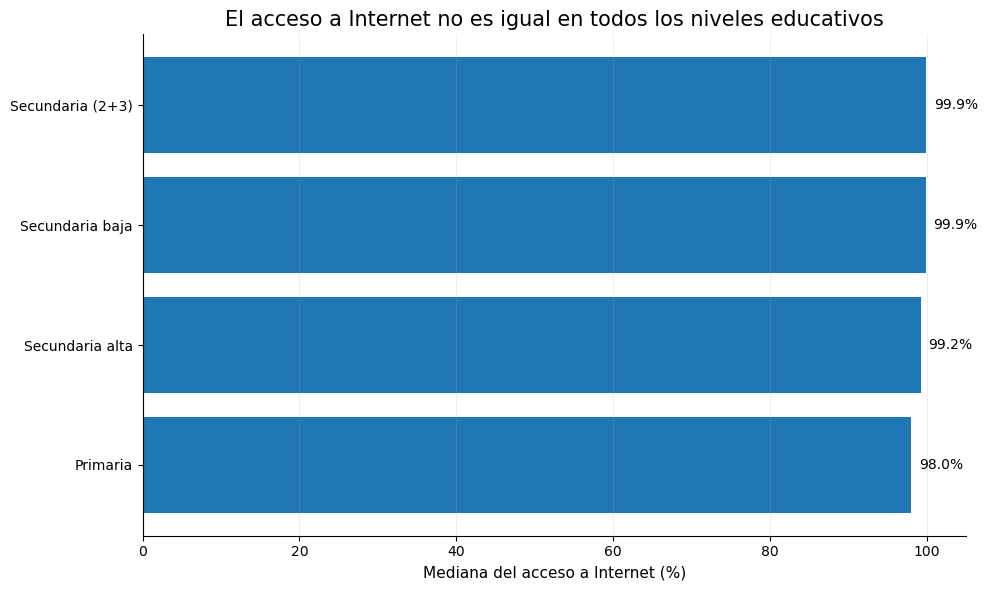

In [23]:
# ============================================================
# CELDA 13 - SEGUNDA PREGUNTA
# ¿TODOS LOS NIVELES EDUCATIVOS TIENEN EL MISMO ACCESO?
# ============================================================

resumen_nivel = (
    datos
    .groupby("NIVEL")
    .agg(
        promedio=("OBS_VALUE", "mean"),
        mediana=("OBS_VALUE", "median"),
        observaciones=("OBS_VALUE", "count")
    )
    .sort_values("mediana", ascending=False)
)

display(resumen_nivel.round(2))

# ============================================================
# CELDA 14 - GRÁFICO 2
# COMPARACIÓN ENTRE NIVELES EDUCATIVOS
# ============================================================

orden_niveles = (
    resumen_nivel
    .sort_values("mediana")
    .index
)

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    orden_niveles,
    resumen_nivel.loc[orden_niveles, "mediana"]
)

ax.set_title(
    "El acceso a Internet no es igual en todos los niveles educativos"
)

ax.set_xlabel("Mediana del acceso a Internet (%)")

ax.set_xlim(0, 105)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(
    axis="x",
    alpha=0.2
)

# Etiquetas directas
for i, nivel in enumerate(orden_niveles):
    
    valor = resumen_nivel.loc[nivel, "mediana"]
    
    ax.text(
        valor + 1,
        i,
        f"{valor:.1f}%",
        va="center"
    )

plt.tight_layout()
plt.show()


In [25]:
# ============================================================
# CELDA 15 - HISTORIA DEL GRÁFICO 2
# ============================================================

nivel_menor = resumen_nivel["mediana"].idxmin()
nivel_mayor = resumen_nivel["mediana"].idxmax()

valor_menor = resumen_nivel.loc[nivel_menor, "mediana"]
valor_mayor = resumen_nivel.loc[nivel_mayor, "mediana"]

print(f"""
HALLAZGO

El nivel con menor mediana de acceso registrado es:

{nivel_menor}: {valor_menor:.2f}%

Mientras que el nivel con mayor mediana es:

{nivel_mayor}: {valor_mayor:.2f}%

Esto nos indica que la brecha digital no necesariamente se
distribuye de la misma manera entre todos los niveles educativos.
""")


# ============================================================
# CELDA 16 - TERCERA PREGUNTA
# ¿CÓMO SE VE LA SITUACIÓN EN EL ÚLTIMO AÑO DISPONIBLE?
# ============================================================

ultimo_año = datos["AÑO"].max()

datos_ultimo = datos[
    datos["AÑO"] == ultimo_año
].copy()

print(
    f"Último año disponible en el archivo: {ultimo_año}"
)

print(
    f"Observaciones disponibles en ese año: "
    f"{len(datos_ultimo)}"
)



HALLAZGO

El nivel con menor mediana de acceso registrado es:

Primaria: 97.99%

Mientras que el nivel con mayor mediana es:

Secundaria (2+3): 99.95%

Esto nos indica que la brecha digital no necesariamente se
distribuye de la misma manera entre todos los niveles educativos.

Último año disponible en el archivo: 2024
Observaciones disponibles en ese año: 55


,promedio,mediana,observaciones
NIVEL,,,
Secundaria alta,88.92,100.00,14
Secundaria (2+3),85.32,99.86,13
Secundaria baja,83.06,99.79,13
Primaria,73.01,97.35,15


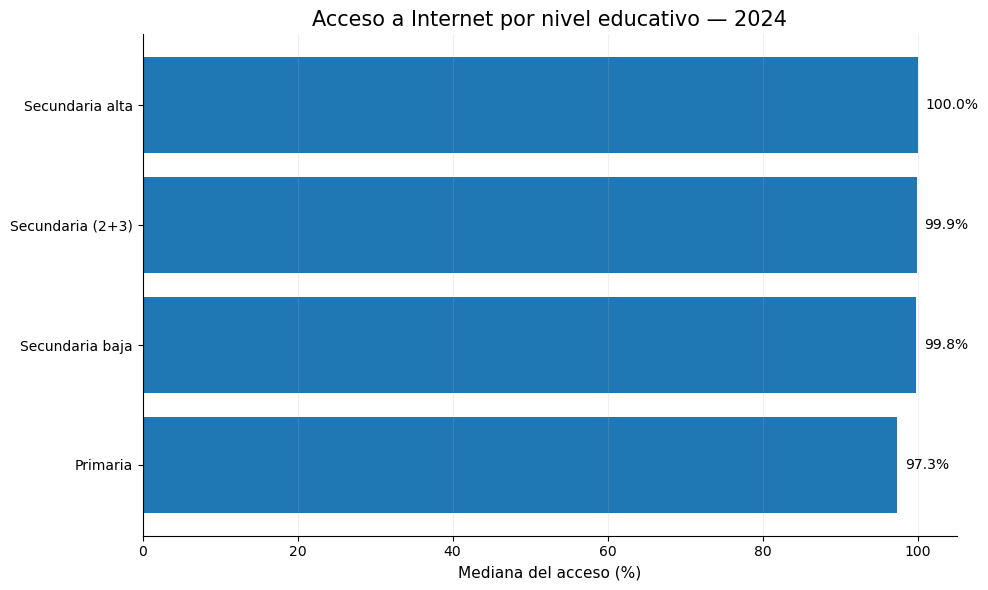

In [27]:

# ============================================================
# CELDA 17 - RESUMEN DEL ÚLTIMO AÑO POR NIVEL
# ============================================================

ultimo_nivel = (
    datos_ultimo
    .groupby("NIVEL")
    .agg(
        promedio=("OBS_VALUE", "mean"),
        mediana=("OBS_VALUE", "median"),
        observaciones=("OBS_VALUE", "count")
    )
    .sort_values("mediana", ascending=False)
)

display(
    ultimo_nivel.round(2)
)

# ============================================================
# CELDA 18 - GRÁFICO 3
# SITUACIÓN DEL ÚLTIMO AÑO
# ============================================================

orden = (
    ultimo_nivel
    .sort_values("mediana")
    .index
)

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    orden,
    ultimo_nivel.loc[orden, "mediana"]
)

ax.set_title(
    f"Acceso a Internet por nivel educativo — {ultimo_año}"
)

ax.set_xlabel("Mediana del acceso (%)")

ax.set_xlim(0, 105)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(
    axis="x",
    alpha=0.2
)

for i, nivel in enumerate(orden):
    
    valor = ultimo_nivel.loc[nivel, "mediana"]
    
    ax.text(
        valor + 1,
        i,
        f"{valor:.1f}%",
        va="center"
    )

plt.tight_layout()
plt.show()

Geografías con los valores más bajos:


,acceso_medio,registros
PAIS,,
Bermuda,19.78,5
Italy,60.16,4
Geografía G00002080,62.51,4
Geografía G00003390,66.68,4
Geografía G00000310,96.51,4
Geografía G00003370,97.40,4
Puerto Rico,98.42,5
Solomon Islands,99.89,4



Geografías con los valores más altos:


,acceso_medio,registros
PAIS,,
Antarctica,100.00,4
Geografía G00001560,100.00,4
Geografía G00001980,100.00,4
"Korea, Republic of",100.00,4
"Virgin Islands, U.S.",100.00,4
Solomon Islands,99.89,4
Puerto Rico,98.42,5
Geografía G00003370,97.40,4


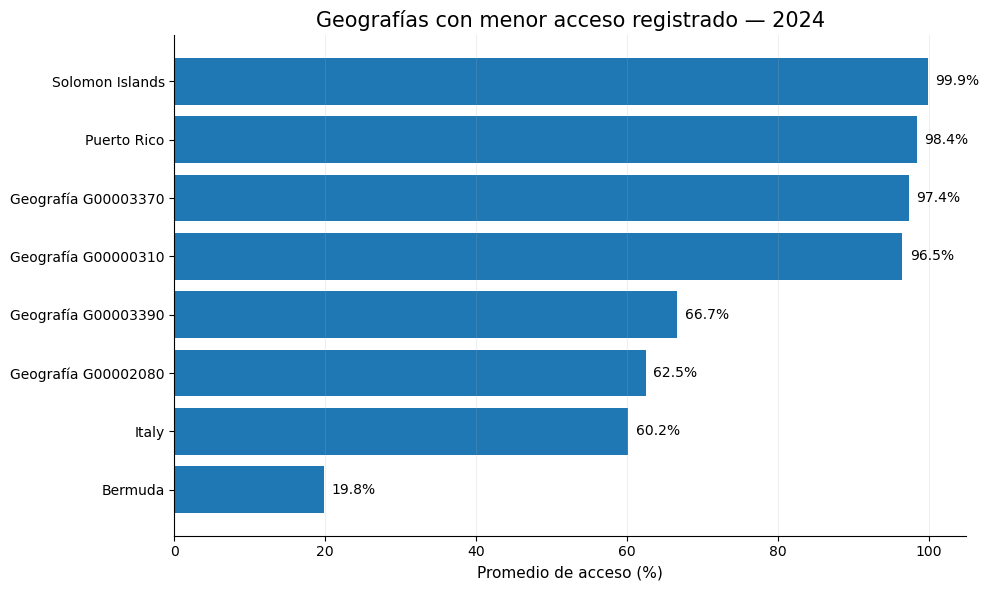

In [29]:
# ============================================================
# CELDA 19 - CUARTA PREGUNTA
# ¿DÓNDE OBSERVAMOS LOS VALORES MÁS ALTOS Y MÁS BAJOS?
# ============================================================

# Para evitar comparar países con información insuficiente,
# utilizamos solamente geografías que tengan al menos 3
# registros educativos en el último año.

comparacion_paises = (
    datos_ultimo
    .groupby("PAIS")
    .agg(
        acceso_medio=("OBS_VALUE", "mean"),
        registros=("OBS_VALUE", "count")
    )
)

comparacion_paises = comparacion_paises[
    comparacion_paises["registros"] >= 3
].sort_values(
    "acceso_medio"
)

print("Geografías con los valores más bajos:")
display(comparacion_paises.head(8).round(2))

print("\nGeografías con los valores más altos:")
display(
    comparacion_paises
    .tail(8)
    .sort_values("acceso_medio", ascending=False)
    .round(2)
)

# ============================================================
# CELDA 20 - GRÁFICO 4
# VALORES MÁS BAJOS
# ============================================================

menores = (
    comparacion_paises
    .head(8)
    .sort_values("acceso_medio")
)

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    menores.index,
    menores["acceso_medio"]
)

ax.set_title(
    f"Geografías con menor acceso registrado — {ultimo_año}"
)

ax.set_xlabel("Promedio de acceso (%)")

ax.set_xlim(0, 105)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(
    axis="x",
    alpha=0.2
)

for i, valor in enumerate(menores["acceso_medio"]):
    
    ax.text(
        valor + 1,
        i,
        f"{valor:.1f}%",
        va="center"
    )

plt.tight_layout()
plt.show()


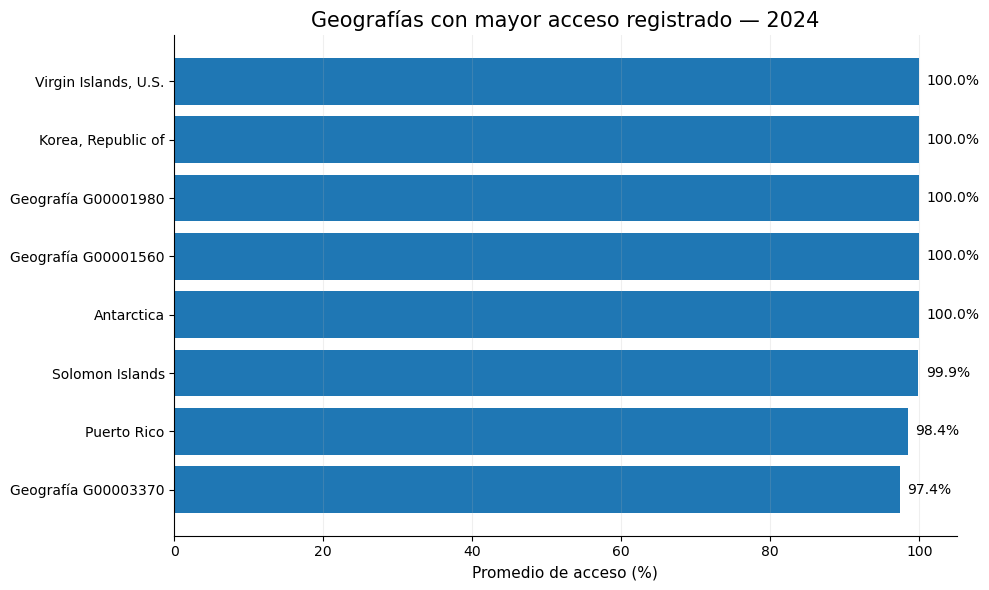

HISTORIA DE DATOS

Nuestro archivo contiene 4,412 registros y cubre el periodo
2000–2024.

La información representa el porcentaje de escuelas con acceso a
Internet para fines pedagógicos.

La primera gran historia que aparece es que muchos de los registros
presentan niveles elevados de acceso, pero la distribución no es
uniforme.

También encontramos diferencias entre niveles educativos.

Finalmente, observamos que la cantidad de información disponible
cambia considerablemente entre años. Esto es importante porque
impide interpretar una sola línea temporal como si representara
una medición perfecta y constante de todo el mundo.

Por lo tanto, la historia no es simplemente:

"Cada vez hay más Internet en las escuelas".

La historia más responsable es:

"El acceso a Internet para fines educativos presenta niveles altos
en una parte importante de los registros, pero todavía existen
diferencias entre niveles educativos y geografías, mientras que la
cobertura de los datos también cambia a 

In [31]:
# ============================================================
# CELDA 21 - GRÁFICO 5
# VALORES MÁS ALTOS
# ============================================================

mayores = (
    comparacion_paises
    .tail(8)
    .sort_values("acceso_medio")
)

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    mayores.index,
    mayores["acceso_medio"]
)

ax.set_title(
    f"Geografías con mayor acceso registrado — {ultimo_año}"
)

ax.set_xlabel("Promedio de acceso (%)")

ax.set_xlim(0, 105)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(
    axis="x",
    alpha=0.2
)

for i, valor in enumerate(mayores["acceso_medio"]):
    
    ax.text(
        valor + 1,
        i,
        f"{valor:.1f}%",
        va="center"
    )

plt.tight_layout()
plt.show()


# ============================================================
# CELDA 22 - RESUMEN AUTOMÁTICO DE LOS HALLAZGOS
# ============================================================

print("=" * 70)
print("HISTORIA DE DATOS")
print("=" * 70)

print(f"""
Nuestro archivo contiene {len(datos):,} registros y cubre el periodo
{datos['AÑO'].min()}–{datos['AÑO'].max()}.

La información representa el porcentaje de escuelas con acceso a
Internet para fines pedagógicos.

La primera gran historia que aparece es que muchos de los registros
presentan niveles elevados de acceso, pero la distribución no es
uniforme.

También encontramos diferencias entre niveles educativos.

Finalmente, observamos que la cantidad de información disponible
cambia considerablemente entre años. Esto es importante porque
impide interpretar una sola línea temporal como si representara
una medición perfecta y constante de todo el mundo.

Por lo tanto, la historia no es simplemente:

"Cada vez hay más Internet en las escuelas".

La historia más responsable es:

"El acceso a Internet para fines educativos presenta niveles altos
en una parte importante de los registros, pero todavía existen
diferencias entre niveles educativos y geografías, mientras que la
cobertura de los datos también cambia a través del tiempo."
""")

In [33]:
# ============================================================
# CELDA 23 - PRINCIPIOS DE VISUALIZACIÓN:
# GESTALT
# ============================================================

display(Markdown("""
## Principios de Gestalt utilizados

### 1. Proximidad
Los elementos relacionados se colocaron cerca unos de otros.
Por ejemplo, las etiquetas de porcentaje aparecen junto a sus barras.

### 2. Similitud
Los elementos que representan la misma variable utilizan una
representación visual consistente.

### 3. Continuidad
En los gráficos temporales se utiliza una línea para facilitar
la percepción de la evolución a través del tiempo.

### 4. Figura y fondo
Se redujeron elementos visuales innecesarios para que los datos
sean la figura principal y el fondo no compita con ellos.

### 5. Cierre
Las estructuras sencillas de los gráficos permiten que el lector
complete visualmente la comparación sin necesitar elementos
decorativos adicionales.
"""))


# ============================================================
# CELDA 24 - PRINCIPIOS DE TUFTE
# ============================================================

display(Markdown("""
## Principios de Edward Tufte utilizados

### 1. Alta proporción de tinta de datos
La mayor parte de los elementos visibles del gráfico representan
información o ayudan directamente a interpretarla.

### 2. Eliminación de "chartjunk"
Se eliminaron adornos, bordes superiores y laterales innecesarios.

### 3. Evitar efectos 3D
No se utilizaron efectos tridimensionales porque pueden dificultar
la comparación de magnitudes.

### 4. Etiquetas directas
Cuando fue posible, se colocaron los valores directamente junto
a las barras en lugar de obligar al lector a buscar una leyenda.

### 5. Escala honesta
Los porcentajes utilizan una escala de 0 a 100%, que corresponde
al significado natural de la variable.

### 6. Datos antes que decoración
El objetivo principal de cada gráfico es comunicar un hallazgo,
no producir un gráfico visualmente complejo.
"""))



## Principios de Gestalt utilizados

### 1. Proximidad
Los elementos relacionados se colocaron cerca unos de otros.
Por ejemplo, las etiquetas de porcentaje aparecen junto a sus barras.

### 2. Similitud
Los elementos que representan la misma variable utilizan una
representación visual consistente.

### 3. Continuidad
En los gráficos temporales se utiliza una línea para facilitar
la percepción de la evolución a través del tiempo.

### 4. Figura y fondo
Se redujeron elementos visuales innecesarios para que los datos
sean la figura principal y el fondo no compita con ellos.

### 5. Cierre
Las estructuras sencillas de los gráficos permiten que el lector
complete visualmente la comparación sin necesitar elementos
decorativos adicionales.



## Principios de Edward Tufte utilizados

### 1. Alta proporción de tinta de datos
La mayor parte de los elementos visibles del gráfico representan
información o ayudan directamente a interpretarla.

### 2. Eliminación de "chartjunk"
Se eliminaron adornos, bordes superiores y laterales innecesarios.

### 3. Evitar efectos 3D
No se utilizaron efectos tridimensionales porque pueden dificultar
la comparación de magnitudes.

### 4. Etiquetas directas
Cuando fue posible, se colocaron los valores directamente junto
a las barras en lugar de obligar al lector a buscar una leyenda.

### 5. Escala honesta
Los porcentajes utilizan una escala de 0 a 100%, que corresponde
al significado natural de la variable.

### 6. Datos antes que decoración
El objetivo principal de cada gráfico es comunicar un hallazgo,
no producir un gráfico visualmente complejo.


In [35]:
# ============================================================
# CELDA 25 - PRINCIPIOS DE NIGEL HOLMES
# ============================================================

display(Markdown("""
## Principios de Nigel Holmes utilizados

### 1. Simplificación
Se evitó mostrar información que no ayudara a responder la pregunta
principal de cada gráfico.

### 2. Jerarquía visual
Los títulos explican directamente qué debe observar el lector.

### 3. Anotación
Los valores importantes se escribieron directamente en los gráficos
para facilitar su interpretación.

### 4. Comunicación antes que decoración
Los gráficos buscan contar una historia y no solamente mostrar
variables.

### 5. Una idea principal por gráfico
Cada visualización intenta responder una pregunta concreta:

- ¿Cómo cambia el indicador con el tiempo?
- ¿Existen diferencias entre niveles educativos?
- ¿Qué ocurre en el último año?
- ¿Dónde aparecen los valores más altos y más bajos?
"""))


# ============================================================
# CELDA 26 - CONCLUSIÓN FINAL
# ============================================================

display(Markdown(f"""
# Conclusión

El análisis del archivo **SE_ACS_INTNT.csv** permite observar la
situación del acceso a Internet en las escuelas para fines
pedagógicos entre **{datos['AÑO'].min()} y {datos['AÑO'].max()}**.

La información muestra que una parte importante de los registros
alcanza niveles elevados de conectividad. Sin embargo, la situación
no es completamente homogénea: existen diferencias entre niveles
educativos y entre las distintas geografías.

Un aspecto especialmente importante es que la cantidad de
observaciones disponibles cambia de un año a otro. Por esta razón,
los resultados deben interpretarse como una descripción de los
registros disponibles y no como una medición perfectamente
comparable de todas las escuelas del mundo en cada año.

La principal enseñanza de esta visualización es que **tener un
porcentaje alto de acceso en muchos registros no significa que la
brecha digital haya desaparecido**. Todavía existen lugares y
niveles educativos donde el acceso registrado es considerablemente
menor.

Por ello, la historia de los datos puede resumirse de la siguiente
manera:

> **La conexión de las escuelas ha avanzado, pero la brecha digital
> educativa todavía puede observarse cuando dejamos de mirar
> únicamente el promedio y comenzamos a comparar niveles,
> geografías y cobertura de los datos.**

En términos de diseño, el notebook aplica principios de **Gestalt,
Tufte y Nigel Holmes**, priorizando la claridad, la comparación,
la reducción de elementos innecesarios y la comunicación de una
historia a partir de los datos.
"""))


## Principios de Nigel Holmes utilizados

### 1. Simplificación
Se evitó mostrar información que no ayudara a responder la pregunta
principal de cada gráfico.

### 2. Jerarquía visual
Los títulos explican directamente qué debe observar el lector.

### 3. Anotación
Los valores importantes se escribieron directamente en los gráficos
para facilitar su interpretación.

### 4. Comunicación antes que decoración
Los gráficos buscan contar una historia y no solamente mostrar
variables.

### 5. Una idea principal por gráfico
Cada visualización intenta responder una pregunta concreta:

- ¿Cómo cambia el indicador con el tiempo?
- ¿Existen diferencias entre niveles educativos?
- ¿Qué ocurre en el último año?
- ¿Dónde aparecen los valores más altos y más bajos?



# Conclusión

El análisis del archivo **SE_ACS_INTNT.csv** permite observar la
situación del acceso a Internet en las escuelas para fines
pedagógicos entre **2000 y 2024**.

La información muestra que una parte importante de los registros
alcanza niveles elevados de conectividad. Sin embargo, la situación
no es completamente homogénea: existen diferencias entre niveles
educativos y entre las distintas geografías.

Un aspecto especialmente importante es que la cantidad de
observaciones disponibles cambia de un año a otro. Por esta razón,
los resultados deben interpretarse como una descripción de los
registros disponibles y no como una medición perfectamente
comparable de todas las escuelas del mundo en cada año.

La principal enseñanza de esta visualización es que **tener un
porcentaje alto de acceso en muchos registros no significa que la
brecha digital haya desaparecido**. Todavía existen lugares y
niveles educativos donde el acceso registrado es considerablemente
menor.

Por ello, la historia de los datos puede resumirse de la siguiente
manera:

> **La conexión de las escuelas ha avanzado, pero la brecha digital
> educativa todavía puede observarse cuando dejamos de mirar
> únicamente el promedio y comenzamos a comparar niveles,
> geografías y cobertura de los datos.**

En términos de diseño, el notebook aplica principios de **Gestalt,
Tufte y Nigel Holmes**, priorizando la claridad, la comparación,
la reducción de elementos innecesarios y la comunicación de una
historia a partir de los datos.
